<a href="https://colab.research.google.com/github/harshithnova/indian-currency-condition-classifier/blob/main/demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Indian Currency Note Condition Classifier: Demo
Upload a photo of a note; the model predicts Crisp / Damaged / Worn with a confidence score.
Uses the saved models from currency_condition_classifier.ipynb (no training here).

Cell 1: setup and load the saved models

In [1]:
# Mount Google Drive to reach the saved models
from google.colab import drive
drive.mount('/content/drive')

# Imports
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

# Paths to the saved models
PROJECT = '/content/drive/MyDrive/CurrencyProject'
cnn_model = keras.models.load_model(PROJECT + '/models/custom_cnn_best.keras')
mob_model = keras.models.load_model(PROJECT + '/models/mobilenet_best.keras')

# Same class order as training (alphabetical folder names)
class_names = ['Crisp', 'Damaged', 'Worn']
print('Models loaded')

Mounted at /content/drive
Models loaded


Cell 2: upload an image and predict

Saving 10_048.jpg to 10_048.jpg


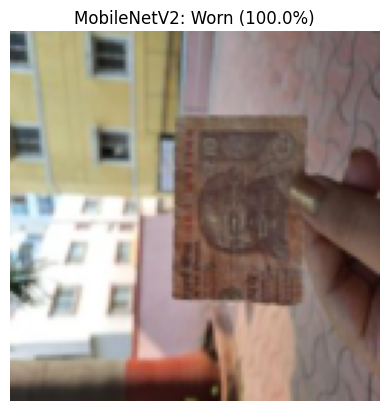

File: 10_048.jpg
MobileNetV2 (main): Worn | confidence: 100.0 %
Custom CNN        : Worn | confidence: 98.9 %



In [4]:
from google.colab import files

# Ask the user to upload one or more images
uploaded = files.upload()

for name in uploaded:
    # Load the image the same way as in training: RGB, 128x128, bilinear resize
    img = keras.utils.load_img(name, target_size=(128, 128), interpolation='bilinear')
    x = keras.utils.img_to_array(img)        # pixel values 0-255
    x = np.expand_dims(x, axis=0)            # a batch of one image

    # Both models scale the pixels themselves, so no extra preprocessing is needed
    mob_probs = mob_model.predict(x, verbose=0)[0]
    cnn_probs = cnn_model.predict(x, verbose=0)[0]

    # Predicted class and confidence for each model
    mob_label = class_names[np.argmax(mob_probs)]
    mob_conf = mob_probs.max()
    cnn_label = class_names[np.argmax(cnn_probs)]
    cnn_conf = cnn_probs.max()

    # Show the image with the main result (MobileNetV2 is the best model)
    plt.imshow(img)
    plt.title('MobileNetV2: ' + mob_label + ' (' + str(round(mob_conf * 100, 1)) + '%)')
    plt.axis('off')
    plt.show()

    print('File:', name)
    print('MobileNetV2 (main):', mob_label, '| confidence:', round(mob_conf * 100, 1), '%')
    print('Custom CNN        :', cnn_label, '| confidence:', round(cnn_conf * 100, 1), '%')

    # Warn when the model is unsure
    if mob_conf < 0.6:
        print('Low confidence: the note may be borderline or unlike the training photos.')
    print()